### 데이터 설명

| 변수명           | 데이터타입 | 설명                        | 범주 값 또는 예시                                                                                                                         |
| ------------- | ----- | ------------------------- | ---------------------------------------------------------------------------------------------------------------------------------- |
| **age**       | 수치형   | 나이                        | -                                                                                                                                  |
| **job**       | 범주형   | 직업                        | admin, unknown, unemployed, management, housemaid, entrepreneur, student, blue-collar, self-employed, retired, technician, service |
| **marital**   | 범주형   | 결혼상태                      | married, divorced,single (사별해도 divorced로 포함)                                                                                                          |
| **education** | 범주형   | 학력                        | unknown, secondary, primary, tertiary                                                                                              |
| **default**   | 범주형   | 신용 채무 불이행 여부              | yes, no                                                                                                                            |
| **balance**   | 수치형   | 연평균 잔액 (단위: 유로)           | -                                                                                                                                  |
| **housing**   | 범주형   | 주택 대출 여부                  | yes, no                                                                                                                            |
| **loan**      | 범주형   | 개인 대출 여부                  | yes, no                                                                                                                            |
| **contact**   | 범주형   | 최근 연락 수단                  | unknown, telephone, cellular                                                                                                       |
| **day**       | 수치형   | 최근 연락 날짜                  | 1 \~ 31                                                                                                                            |
| **month**     | 범주형   | 최근 연락한 달                  | jan, feb, mar, ..., dec                                                                                                            |
| **duration**  | 수치형   | 최근 통화 시간 (초)              | -                                                                                                                                  |
| **campaign**  | 수치형   | 이번 캠페인 중 고객에게 연락한 횟수      | -                                                                                                                                  |
| **pdays**     | 수치형   | 이전 캠페인 이후 경과일 (-1은 연락 없음) | -                                                                                                                                  |
| **previous**  | 수치형   | 이전 캠페인에서 고객에게 연락한 횟수      | -                                                                                                                                  |
| **poutcome**  | 범주형   | 이전 캠페인 결과                 | unknown, other, failure, success                                                                                                   |
| **label**     | 범주형   | 정기예금 가입 여부 (타겟 변수)        | 1 = 가입, 0 = 미가입                                                                                                                    |


### 범주형 변수

- 범주형 비율 해석

    - job
        - student, retired, unemployed : 양수 -> 가입자 비중이 더 높음
        - blue-collar, services : 음수 -> 마케팅 효율이 낮은 직업에 해당

    - education
        - tertiary  > 양수에 해당하므로 고학력자일 수록 정기예금에 관심이 많다는 것을 해석할 수 있음
    
    - contact
        - cellular : 휴대폰에 해당하는데 이로 연락을 했을 때 가입할 확률이 올라감
    
    - month
        - mar apr, oct, sep : 양수 
        - may : significantly : 음수

    - martial
        - single : 양수 
            -> 독신일 경우 독립적이기에 가입가능성이 올라가는 것으로 해석 가능
        
        - married : 음수 

    - poutcome 
        - success : 이전 캠페인시 성공시 가입확률 올라감
        - unknown : 과거 기록이 없을 때는 음수일 경우가 많기에 주의

    - default, loan, housing
        - 신용 불이행 X, 대출이 없을 수록 가입확률이 높아짐


### train_test data 나누기

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from lightgbm import LGBMClassifier
import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31647 entries, 0 to 31646
Data columns (total 18 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         31647 non-null  object
 1   age        31647 non-null  int64 
 2   job        31647 non-null  object
 3   marital    31647 non-null  object
 4   education  31647 non-null  object
 5   default    31647 non-null  object
 6   balance    31647 non-null  int64 
 7   housing    31647 non-null  object
 8   loan       31647 non-null  object
 9   contact    31647 non-null  object
 10  day        31647 non-null  int64 
 11  month      31647 non-null  object
 12  duration   31647 non-null  int64 
 13  campaign   31647 non-null  int64 
 14  pdays      31647 non-null  int64 
 15  previous   31647 non-null  int64 
 16  poutcome   31647 non-null  object
 17  label      31647 non-null  int64 
dtypes: int64(8), object(10)
memory usage: 4.3+ MB


### 통화시간 EDA

In [4]:
min_duration = df['duration'].min()
max_duration = df['duration'].max()
median_duration = df['duration'].mean()
standard_dev_duration = df["duration"].std()

print("Min call duration: ", min_duration)
print("Max call duration: ", max_duration)
print("Median call duration: ", round(median_duration, 2))
print("Standard diveation in call duration: ", round(standard_dev_duration, 2))

Min call duration:  0
Max call duration:  3881
Median call duration:  258.09
Standard diveation in call duration:  255.74


In [5]:
first_quartile = df['duration'].quantile(q = 0.25)
second_quartile = df['duration'].quantile(q = 0.50)
third_quartile = df['duration'].quantile(q = 0.75)
fourth_quartile = df['duration'].quantile(q = 1)
IRQ = third_quartile - second_quartile

print("Second Quartile: ", second_quartile)
print("Third Quartile: ", third_quartile)
print("Inter quartile range(range within which most data is present): ",IRQ)

Second Quartile:  180.0
Third Quartile:  320.0
Inter quartile range(range within which most data is present):  140.0


Text(0.5, 1.0, 'Count of contacts made in each month')

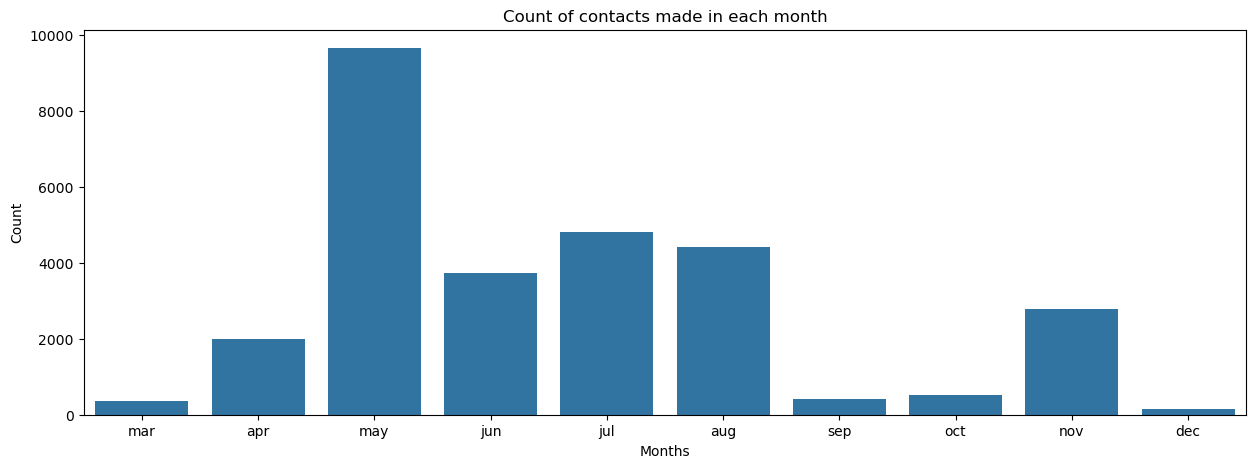

In [6]:
# For Months
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize = (15, 5))
sns.countplot(x = 'month', data = df, order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'])
ax.set_xlabel("Months")
ax.set_ylabel("Count")
ax.set_title("Count of contacts made in each month")

Text(0.5, 1.0, 'log(Duration) vs Jobs')

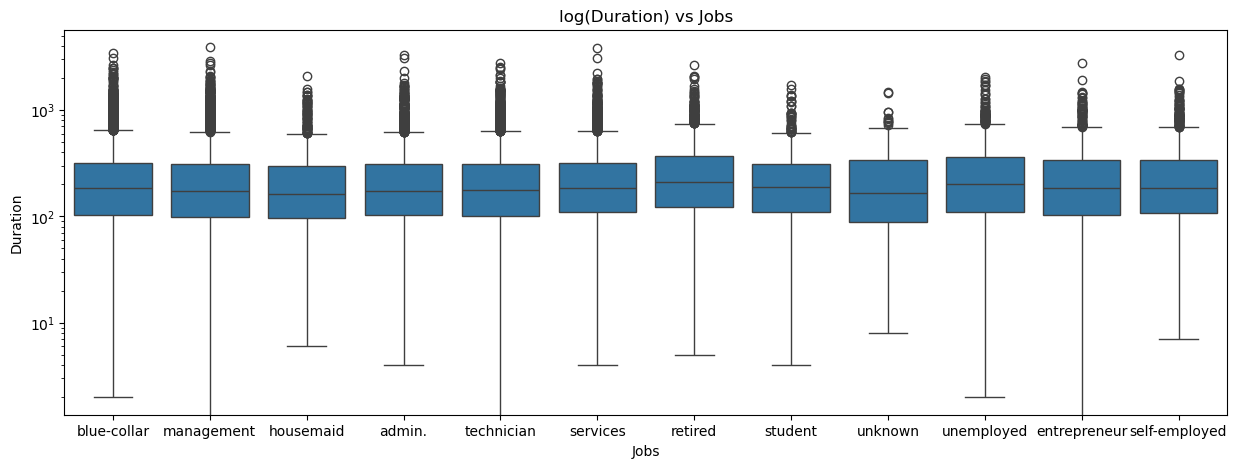

In [7]:
#job duration
fig, ax = plt.subplots(figsize = (15, 5))
sns.boxplot(x = "job", y = "duration", data = df, orient = 'v')
ax.set_xlabel("Jobs")
ax.set_ylabel("Duration")
ax.set_yscale("log")
ax.set_title("log(Duration) vs Jobs")

Text(0.5, 1.0, 'log(Duration) vs Education')

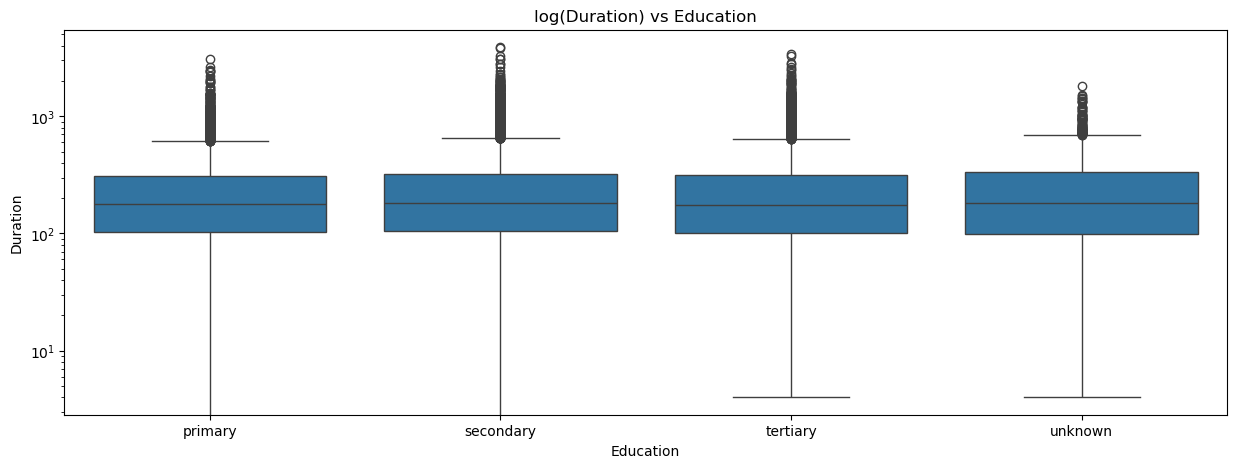

In [8]:
fig, ax = plt.subplots(figsize = (15, 5))
sns.boxplot(x = "education", y = "duration", data = df, orient = 'v')
ax.set_xlabel("Education")
ax.set_ylabel("Duration")
ax.set_yscale("log")
ax.set_title("log(Duration) vs Education")

### Unknown 에 대한 정의

In [ ]:
# unknown job 에 따라서 university 에 대해 

In [4]:
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
binary_cols = ['default', 'housing', 'loan']   
cat_cols = ['job', 'marital', 'education', 'contact', 'month', 'poutcome']
y_col = ['label']

In [10]:
#범주형 변수별 unknown 비율
for col in cat_cols:
    total = df.shape[0]
    unknown_cnt = (df[col] == 'unknown').sum()
    ratio = unknown_cnt / total
    print(f"{col}: {unknown_cnt} / {total} = {ratio:.4%}")

    

job: 198 / 31647 = 0.6257%
marital: 0 / 31647 = 0.0000%
education: 1275 / 31647 = 4.0288%
contact: 9082 / 31647 = 28.6978%
month: 0 / 31647 = 0.0000%
poutcome: 25918 / 31647 = 81.8972%


In [19]:
# unkown 이 라벨 1 에 해당할 확률 각 범주별로.

overall_label_dist = df['label'].value_counts(normalize=True)
print(overall_label_dist)
print()

for col in cat_cols:
    unknown_df = df[df[col] == 'unknown']
    if not unknown_df.empty:
        label_dist = unknown_df['label'].value_counts(normalize=True)
        print(f"{col} : (총 {len(unknown_df)}개)")
        print(label_dist)
        print()


label
0    0.883022
1    0.116978
Name: proportion, dtype: float64

job : (총 198개)
label
0    0.878788
1    0.121212
Name: proportion, dtype: float64

education : (총 1275개)
label
0    0.865098
1    0.134902
Name: proportion, dtype: float64

contact : (총 9082개)
label
0    0.958489
1    0.041511
Name: proportion, dtype: float64

poutcome : (총 25918개)
label
0    0.907439
1    0.092561
Name: proportion, dtype: float64



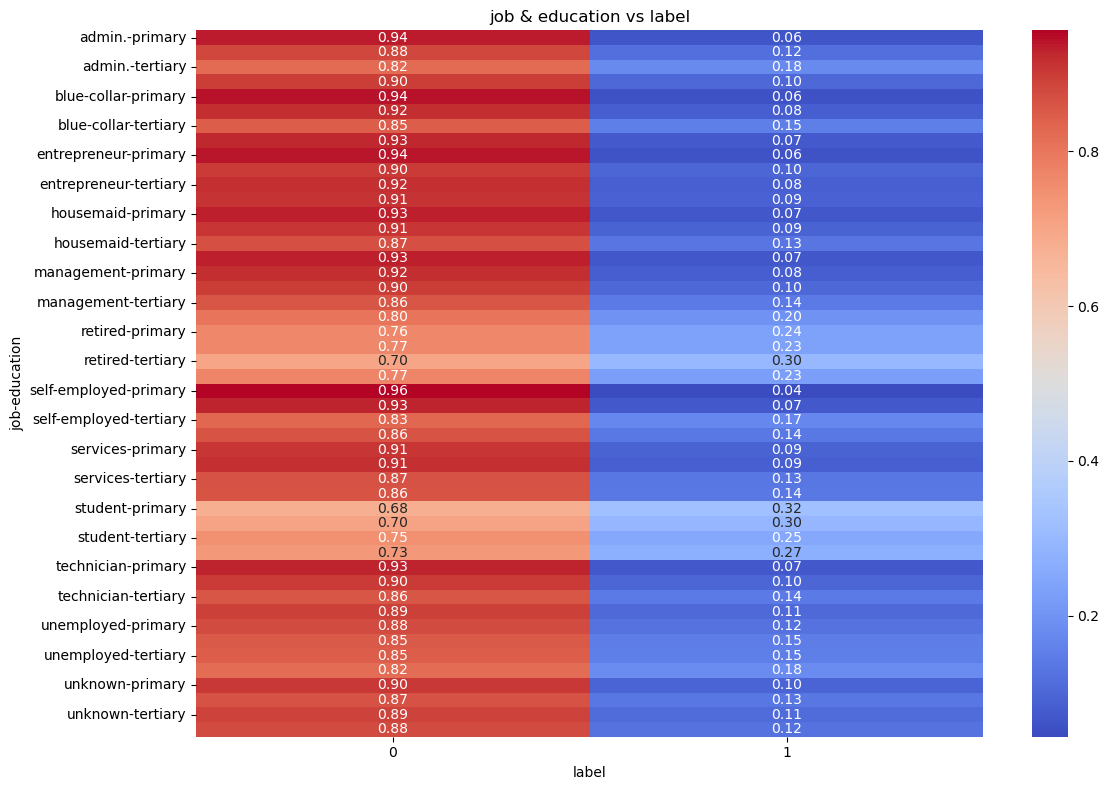

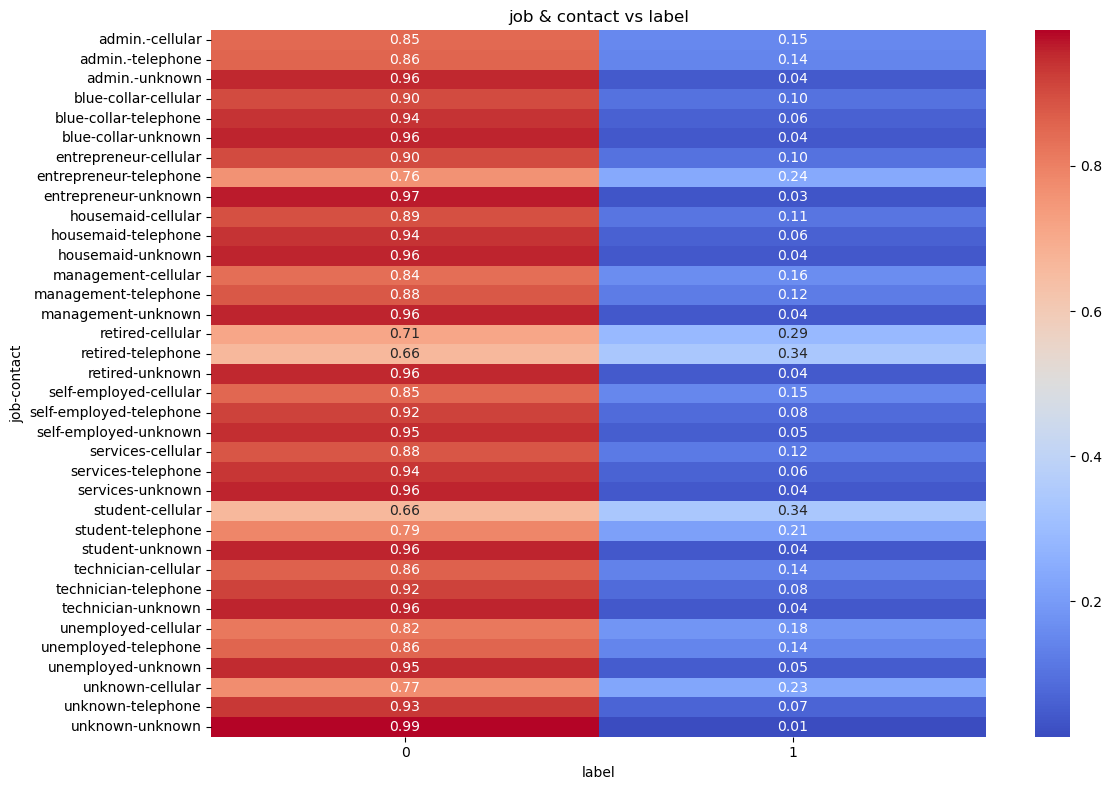

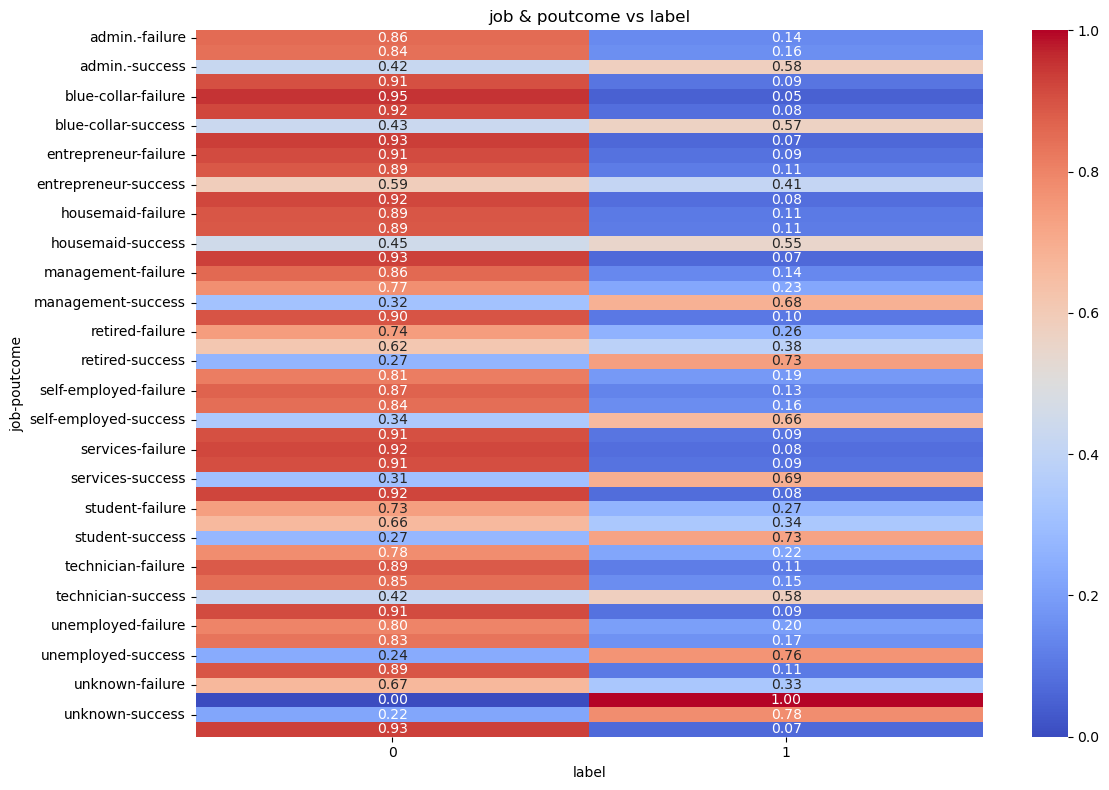

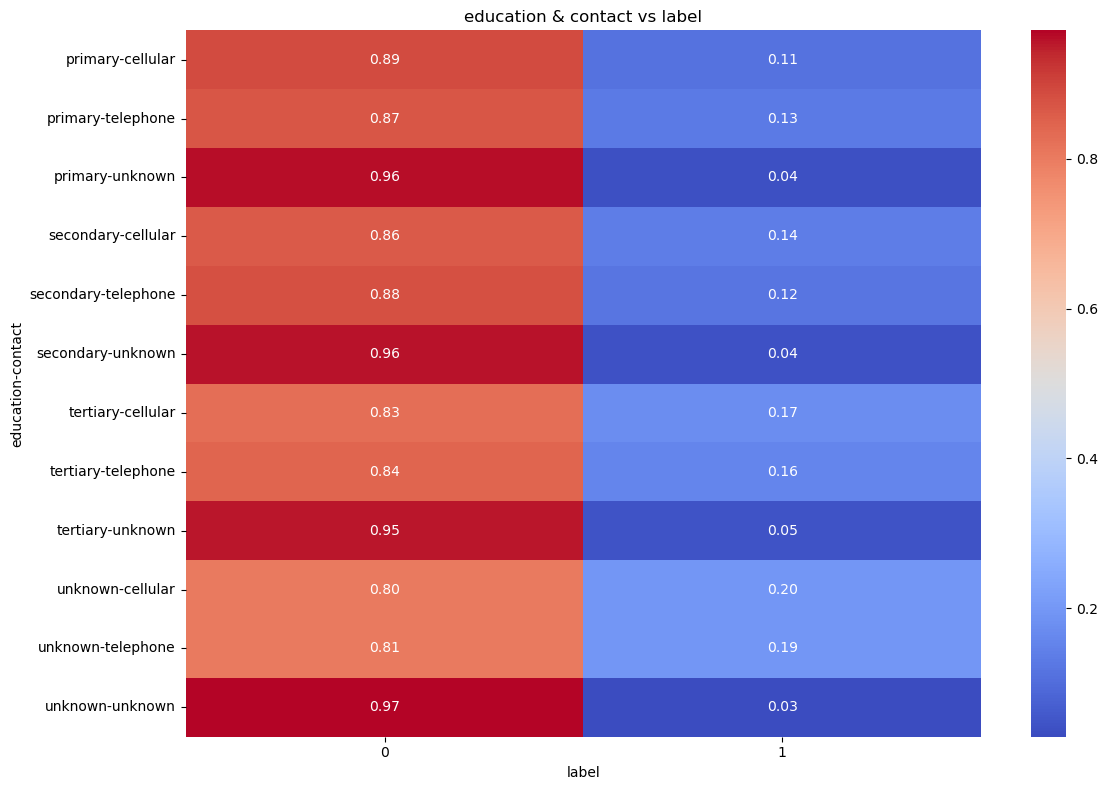

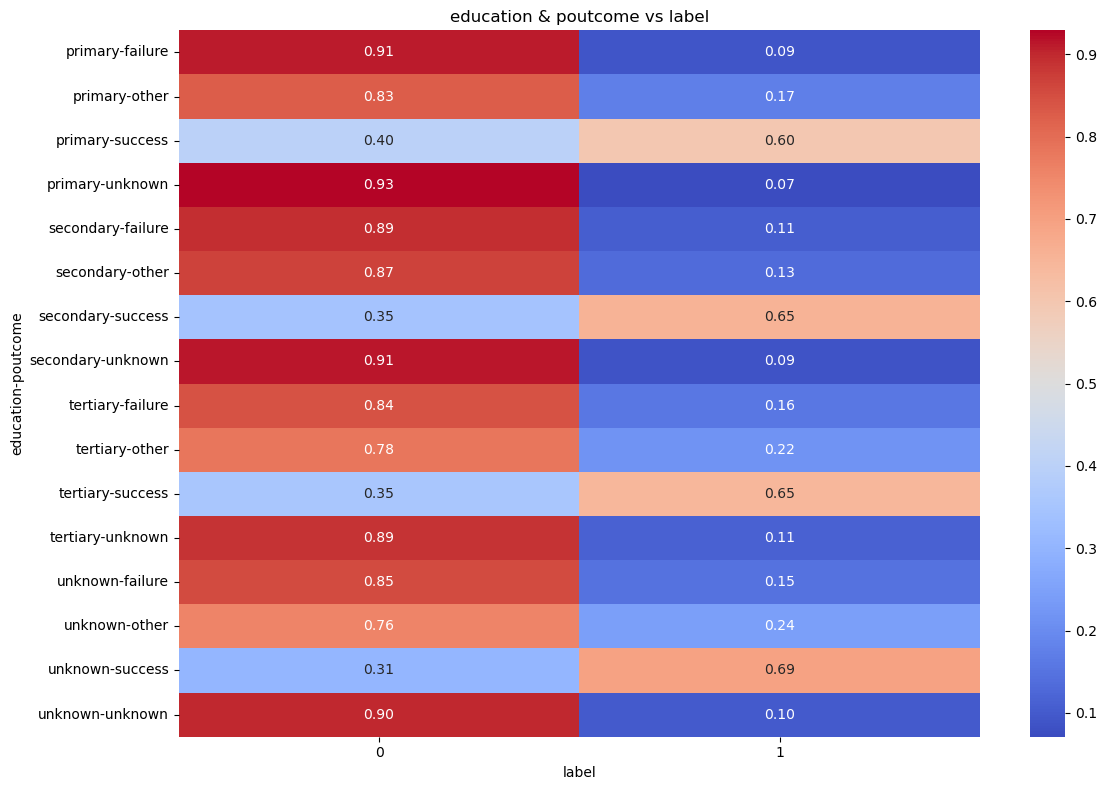

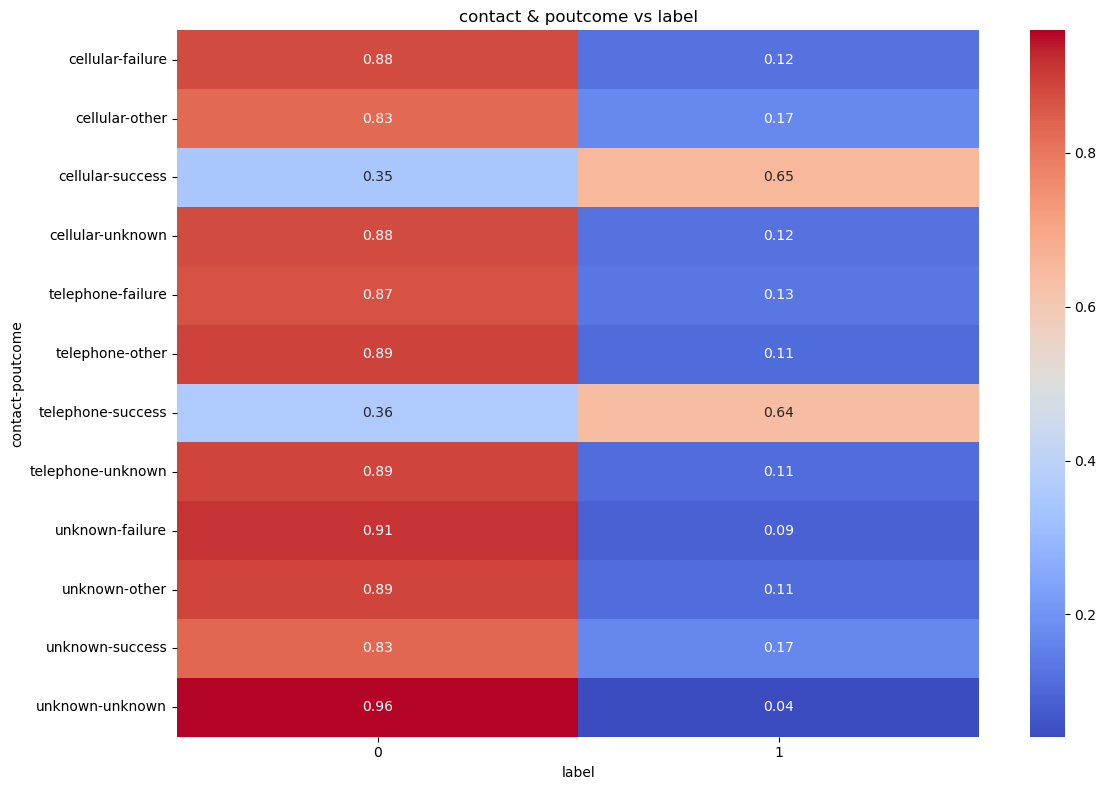

In [8]:
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

unknown_cols = ['job', 'education', 'contact', 'poutcome']

pairs = list(itertools.combinations(unknown_cols, 2))

for pair in pairs:
    idx, col = pair
    cross_tab = pd.crosstab([df[idx], df[col]], df['label'], normalize='index')
    plt.figure(figsize=(12,8))
    sns.heatmap(cross_tab, annot=True, fmt='.2f', cmap='coolwarm')
    plt.title(f'{idx} & {col} vs label')
    plt.tight_layout()
    plt.show()

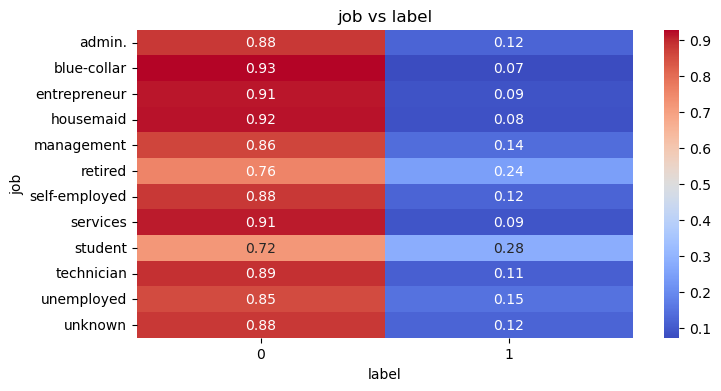

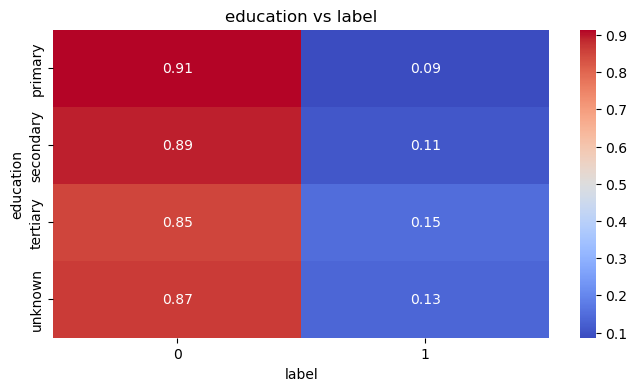

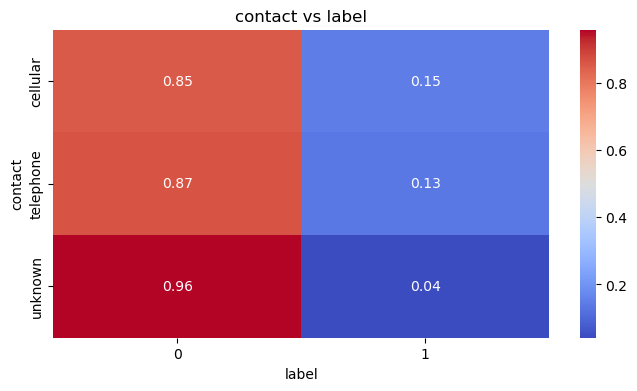

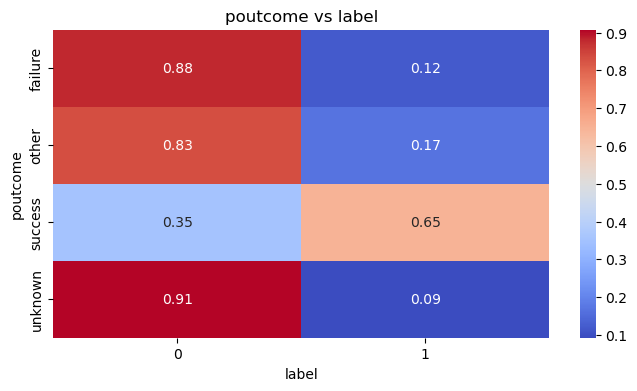

In [7]:
unknown_cols = ['job', 'education', 'contact', 'poutcome']

for col in unknown_cols:
    cross_tab = pd.crosstab(df[col], df['label'], normalize='index')
    plt.figure(figsize=(8,4))
    sns.heatmap(cross_tab, annot=True, fmt='.2f', cmap='coolwarm')
    plt.title(f'{col} vs label')
    plt.show()


In [17]:
X = df.drop(['label'], axis=1)
y = df['label']
X_test = test.copy()

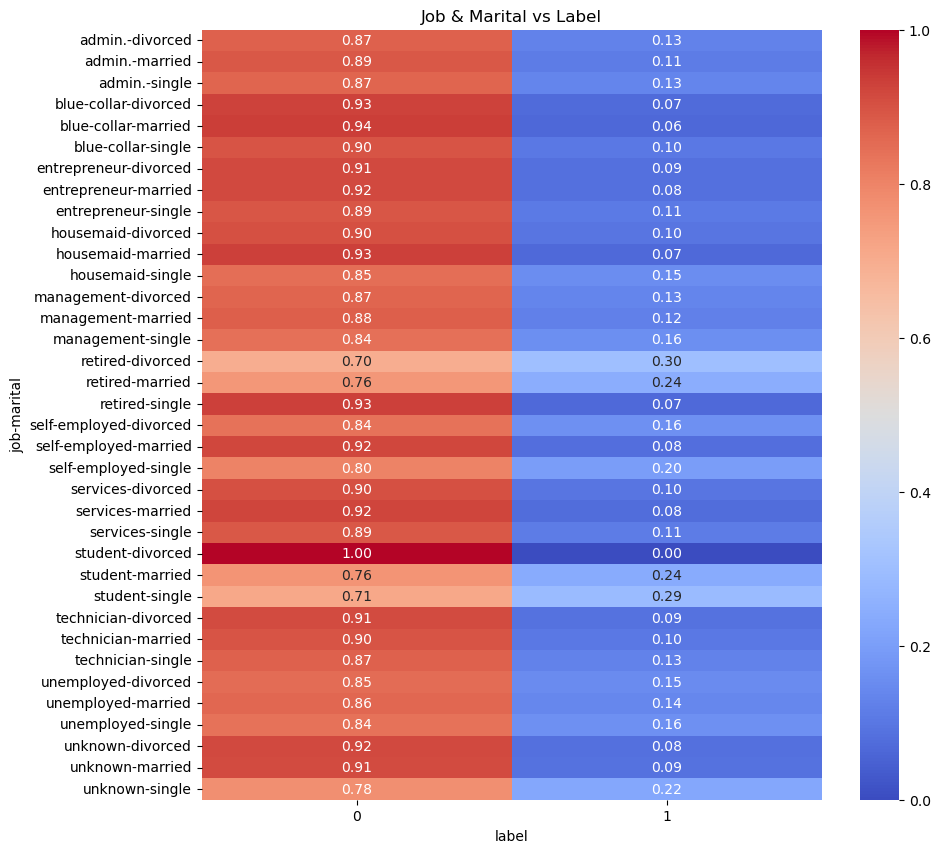

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
cross_tab = pd.crosstab([df['job'], df['marital']], df['label'], normalize='index')
plt.figure(figsize=(10, 10))
sns.heatmap(cross_tab, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Job & Marital vs Label')
plt.show()

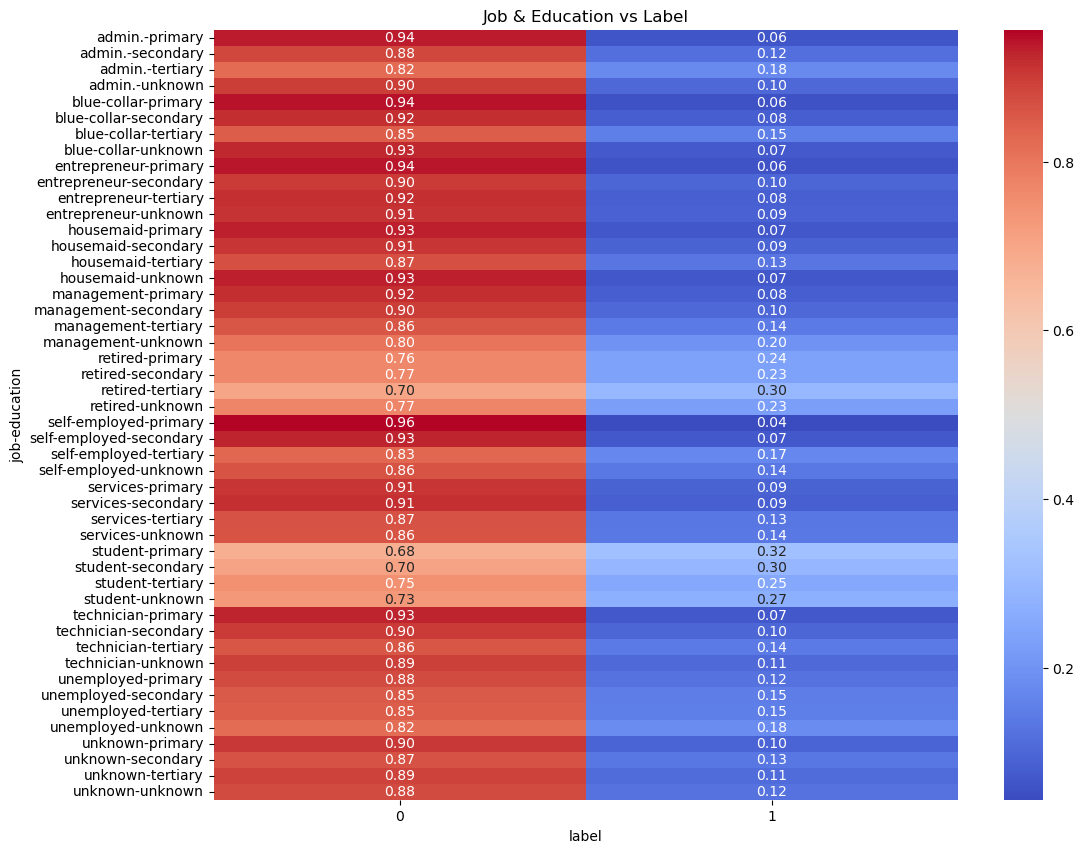

In [13]:
# job과 education의 조합별로 label 비율 확인
cross_tab = pd.crosstab([df['job'], df['education']], df['label'], normalize='index')

plt.figure(figsize=(12, 10))
sns.heatmap(cross_tab, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Job & Education vs Label')
plt.show()

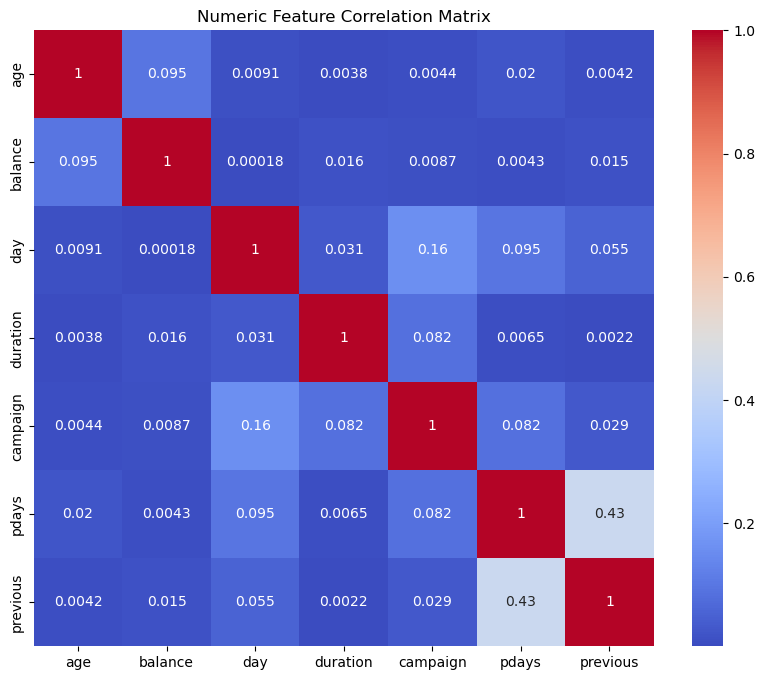

상관관계 0.9 이상 쌍: []


In [15]:
import seaborn as sns

# 상관관계 행렬
corr_matrix = df[num_cols].corr().abs()

# 히트맵 시각화
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Numeric Feature Correlation Matrix")
plt.show()

# 상관계수 0.9 이상인 변수 쌍 찾기 (자기 자신 제외)
high_corr = [(col1, col2, corr_matrix.loc[col1, col2])
             for col1 in num_cols
             for col2 in num_cols
             if col1 != col2 and corr_matrix.loc[col1, col2] > 0.9]

print("상관관계 0.9 이상 쌍:", high_corr)


In [ ]:
month_map = {'jan':1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6,
             'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12}
X['month_num'] = X['month'].map(month_map)
X_test['month_num'] = X_test['month'].map(month_map)

# 기준 여름방학(5, 6, 7, 8월) / 겨울방학(12, 1월)
X['is_summer_vacation'] = X['month_num'].isin([6,7,8,9]).astype(int)
X['is_winter_vacation'] = X['month_num'].isin([12,1]).astype(int)

X_test['is_summer_vacation'] = X_test['month_num'].isin([5,6,7,8]).astype(int)
X_test['is_winter_vacation'] = X_test['month_num'].isin([12,1]).astype(int)

# 방학 전체로 합치려면
X['is_vacation'] = X['month_num'].isin([6,7,8,12,1]).astype(int)
X_test['is_vacation'] = X_test['month_num'].isin([6,7,8,12,1]).astype(int)


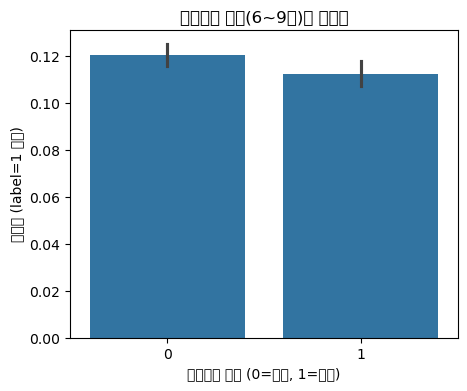

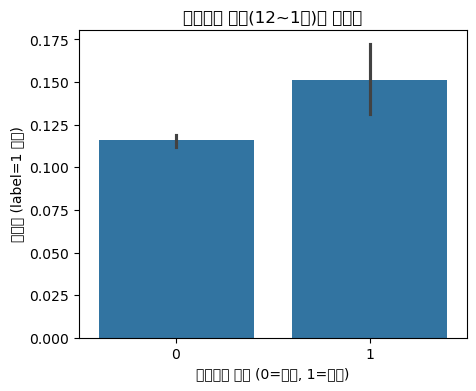

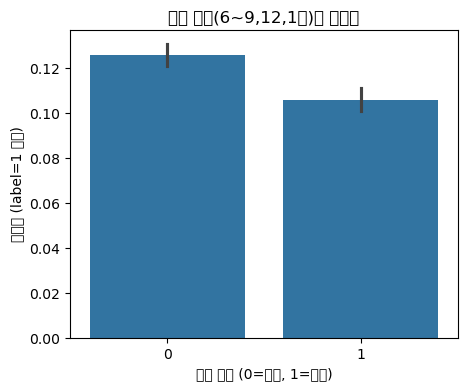

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# is_summer_vacation_eu 기준
plt.figure(figsize=(5,4))
sns.barplot(x='is_summer_vacation', y='label', data=pd.concat([X, y], axis=1))
plt.title("여름방학 기간(6~9월)별 가입률")
plt.xlabel("여름방학 여부 (0=아님, 1=방학)")
plt.ylabel("가입률 (label=1 비율)")
plt.show()

# is_winter_vacation_eu 기준
plt.figure(figsize=(5,4))
sns.barplot(x='is_winter_vacation', y='label', data=pd.concat([X, y], axis=1))
plt.title("겨울방학 기간(12~1월)별 가입률")
plt.xlabel("겨울방학 여부 (0=아님, 1=방학)")
plt.ylabel("가입률 (label=1 비율)")
plt.show()

# is_vacation_eu 기준
plt.figure(figsize=(5,4))
sns.barplot(x='is_vacation', y='label', data=pd.concat([X, y], axis=1))
plt.title("방학 기간(6~9,12,1월)별 가입률")
plt.xlabel("방학 여부 (0=아님, 1=방학)")
plt.ylabel("가입률 (label=1 비율)")
plt.show()


In [ ]:
X_enc = pd.get_dummies(X, drop_first=False)
print(X_enc.columns)

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous',
       'is_single', 'is_education_tertiary', 'is_retired',
       ...
       'job_education_unknown_unknown', 'age_bin_18-25', 'age_bin_26-35',
       'age_bin_36-45', 'age_bin_46-60', 'age_bin_60+', 'season_fall',
       'season_spring', 'season_summer', 'season_winter'],
      dtype='object', length=31765)


In [ ]:
# month 변수는 이미 인코딩되어 있을 수도 있고, 아니면 문자 그대로일 수도 있음

# 문자 그대로 month가 있다면:
def make_season_features(df):
    # 문자 -> 숫자 mapping
    month_map = {'jan':1, 'feb':2, 'mar':3, 'apr':4, 'may':5, 'jun':6,
                 'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12}
    df['month_num'] = df['month'].map(month_map)

    # 유럽 방학 시즌(6~9월)
    df['is_summer'] = df['month_num'].isin([6,7,8,9]).astype(int)
    # 겨울 휴일 시즌(12, 1월)
    df['is_winter'] = df['month_num'].isin([12,1]).astype(int)
    # 미국식 방학(5~8월)
    df['is_holiday'] = df['month_num'].isin([5,6,7,8]).astype(int)

    return df

# 사용 예시
X = make_season_features(X)


# unknown 대체
=> 

## PipeLine

#### 범주형 변수 pipeline 작성

- one hot encoder : binary 변수 일때 사용
    - 'default', 'loan', 'housing' (Y/N) , 'marital', 'contact' (유의미한 most_frequent에 해당하는 범주가 있음)
- target encder : 범주와 타겟간의 연관성이 명확할 때 사용
    - job, poutcome,
- ordinal encoder : 순서 있는 범주에 사용
    - education

In [36]:
def binary(X):
    X = X.copy()
    for col in binary_cols:
        X[col] = X[col].map({'yes': 1, 'no': 0})
    return X

binary_transformer = FunctionTransformer(binary)

transformer = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('bin', binary_transformer, binary_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

In [37]:
model_pipeline = Pipeline(steps=[
    ('preprocessor', transformer),
    ('model', LGBMClassifier(
        boosting_type='gbdt',         
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=64,
        subsample=0.5,
        colsample_bytree=1,
        random_state=42
    ))
])

In [38]:
param_grid = {
    'model__boosting_type': ['gbdt', 'dart'],
    'model__n_estimators': [1000, 1500],
    'model__learning_rate': [0.01, 0.05, 0.1],
    'model__num_leaves': [64],
    'model__subsample': [0.5],
    'model__colsample_bytree': [1]
}

In [39]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(model_pipeline, param_grid, cv=cv, scoring='f1', n_jobs=-1, verbose=2)
grid.fit(X, y)

print("best 파라미터:", grid.best_params_)
print("best F1-score:", grid.best_score_)


Fitting 10 folds for each of 12 candidates, totalling 120 fits
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008331 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1021
[LightGBM] [Info] Number of data points in the train set: 28482, number of used features: 48
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116986 -> initscore=-2.021285
[LightGBM] [Info] Start training from score -2.021285
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003529 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if m

/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=gbdt, model__colsample_bytree=1, model__learning_rate=0.01, model__n_estimators=1000, model__num_leaves=64, model__subsample=0.5; total time= 1.4min


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=gbdt, model__colsample_bytree=1, model__learning_rate=0.01, model__n_estimators=1000, model__num_leaves=64, model__subsample=0.5; total time= 1.4min
[LightGBM] [Info] Number of positive: 3332, number of negative: 25150
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004808 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1022
[LightGBM] [Info] Number of data points in the train set: 28482, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116986 -> initscore=-2.021285
[LightGBM] [Info] Start training from score -2.021285


...

[CV] END model__boosting_type=dart, model__colsample_bytree=1, model__learning_rate=0.1, model__n_estimators=1500, model__num_leaves=64, model__subsample=0.5; total time= 3.2min


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=dart, model__colsample_bytree=1, model__learning_rate=0.1, model__n_estimators=1500, model__num_leaves=64, model__subsample=0.5; total time= 3.0min


/opt/anaconda3/envs/pytorch/lib/python3.11/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[CV] END model__boosting_type=dart, model__colsample_bytree=1, model__learning_rate=0.1, model__n_estimators=1500, model__num_leaves=64, model__subsample=0.5; total time= 2.7min
[LightGBM] [Info] Number of positive: 3702, number of negative: 27945
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000955 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1022
[LightGBM] [Info] Number of data points in the train set: 31647, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116978 -> initscore=-2.021365
[LightGBM] [Info] Start training from score -2.021365
best 파라미터: {'model__boosting_type': 'gbdt', 'model__colsample_bytree': 1, 'model__learning_rate': 0.01, 'model__n_estimators': 1000, 'model__num_leaves': 64, 'model__subsample': 0.5}
best F1-score: 0.5466459321484027


In [40]:
import json

# GridSearchCV를 돌린 뒤 (예: grid.fit(...))
best_params1 = grid.best_params_

# 저장 (예: best_params.json)
with open("best_params1.json", "w") as f:
    json.dump(best_params1, f)

In [41]:
# 전체 train으로 재학습
best_model = grid.best_estimator_
best_model.fit(X, y)

# 테스트 데이터 예측
test_pred = best_model.predict(X_test)

[LightGBM] [Info] Number of positive: 3702, number of negative: 27945
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000986 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1022
[LightGBM] [Info] Number of data points in the train set: 31647, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.116978 -> initscore=-2.021365
[LightGBM] [Info] Start training from score -2.021365


## Submission

In [42]:
submission = pd.read_csv("submission_example.csv")
submission['label'] = test_pred  # 실제 제출 양식에 맞게 컬럼명 변경
submission.to_csv('submission_try02.csv', index=False)